# 2. Explore the Data

**Research question.** Using only information available when an order is approved, how accurately can we predict which orders will arrive after the promised delivery date, and which factors contribute most to that risk?


In [ ]:

import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name in ("wip", "notebooks") else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config                     
from src.data import time_split            
from src.evaluation import cv_splitter      

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

DATA_PATH = ROOT / "data" / "processed" / "olist_final.csv"
FIG_DIR = config.FIG_DIR                     
TABLE_DIR = ROOT / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- One consistent, colour-blind-safe palette ---------------------------------
ON_TIME, LATE = "#2a78d6", "#eb6834"         # blue = on time, orange = late, everywhere
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#9ec5f4", "#f0efec", "#f1a2a1", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})
pct = mtick.PercentFormatter(1.0, decimals=0)
def tidy_log_axis(ax):
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}"))
    ax.xaxis.set_minor_formatter(mtick.NullFormatter())
def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png"); plt.show()

## 1. Load the data and apply the time split (D6)

`olist_final.csv` already contains the agreed population (D2–D4: delivered orders bought from Jan 2017, promised by 1 Aug 2018 to avoid right-censoring). We split it with the shared `time_split` and, from here on, only look at **train**. For the test period we record just its size and late rate, which are already published in `DECISIONS.md`. That way no other test-set information shapes the EDA.

In [2]:
ts_cols = ["order_purchase_timestamp", "order_approved_at",
           "order_delivered_customer_date", "order_estimated_delivery_date"]
df = pd.read_csv(DATA_PATH, parse_dates=ts_cols)
train, test = time_split(df)
train = train.sort_values("order_purchase_timestamp").reset_index(drop=True)   # needed for TimeSeriesSplit
n_test, test_rate = len(test), test.is_late.mean()
del test                                                                       # not used again

print(f"All eligible orders : {len(df):,}  (late {df.is_late.mean():.1%})")
print(f"Train (bought before {config.TEST_START.date()}): {len(train):,} orders, "
      f"{train.is_late.sum():,} late ({train.is_late.mean():.1%}), "
      f"{train.order_purchase_timestamp.min().date()} → {train.order_purchase_timestamp.max().date()}")
print(f"Test  (not explored): {n_test:,} orders, late rate {test_rate:.1%}")

All eligible orders : 85,371  (late 7.0%)
Train (bought before 2018-04-01): 64,038 orders, 5,110 late (8.0%), 2017-01-05 → 2018-03-31
Test  (not explored): 21,333 orders, late rate 4.1%


## 2. The target: `is_late`

Defined in D3: `is_late = 1` when the order reached the customer on a **later calendar day** than the promised date. We confirm the column matches that rule, then look at balance, how it moves over time, and what that means for the time-series CV folds.

is_late matches the calendar-day rule (D3): 100.00% of training orders
A timestamp rule would wrongly flag 776 same-day deliveries as late

On time: 58,928 (92.0%)   Late: 5,110 (8.0%)   Imbalance ≈ 11.5:1
Accuracy of 'always on time' on train: 92.0% (catches 0 late orders)


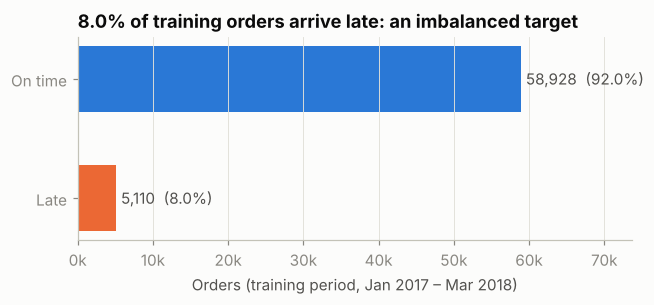

In [3]:
by_day = (train.order_delivered_customer_date.dt.normalize() > train.order_estimated_delivery_date).astype(int)
by_ts  = (train.order_delivered_customer_date > train.order_estimated_delivery_date).astype(int)
print(f"is_late matches the calendar-day rule (D3): {(by_day == train.is_late).mean():.2%} of training orders")
print(f"A timestamp rule would wrongly flag {((by_ts == 1) & (train.is_late == 0)).sum():,} same-day deliveries as late")

counts = train.is_late.value_counts().sort_index()
print(f"\nOn time: {counts[0]:,} ({counts[0]/len(train):.1%})   Late: {counts[1]:,} ({counts[1]/len(train):.1%})   "
      f"Imbalance ≈ {counts[0]/counts[1]:.1f}:1")
print(f"Accuracy of 'always on time' on train: {counts[0]/len(train):.1%} (catches 0 late orders)")

fig, ax = plt.subplots(figsize=(6.5, 2.4))
ax.barh(["Late", "On time"], [counts[1], counts[0]], color=[LATE, ON_TIME], height=0.55)
for y_, v in zip([0, 1], [counts[1], counts[0]]):
    ax.text(v + len(train) * 0.01, y_, f"{v:,}  ({v/len(train):.1%})", va="center", color=INK2)
ax.set_xlim(0, counts[0] * 1.25); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))
ax.set_xlabel("Orders (training period, Jan 2017 – Mar 2018)")
ax.set_title(f"{train.is_late.mean():.1%} of training orders arrive late: an imbalanced target")
save(fig, "01_target_balance")

**Takeaway: the target.**
* **Training period: 64,038 orders, 5,110 late (8.0%), an imbalance of about 11.5 to 1.** Predicting "on time" for every order would score 92.0% accuracy and catch no late orders, which is why D8 uses PR-AUC and recall in the top 10% rather than accuracy.
* The label follows D3 exactly (100% match). A timestamp rule would have wrongly marked 776 same-day deliveries as late.
* For context only (published in `DECISIONS.md`, not explored here): the test period has 21,333 orders at **4.1%** late, about half the training rate.

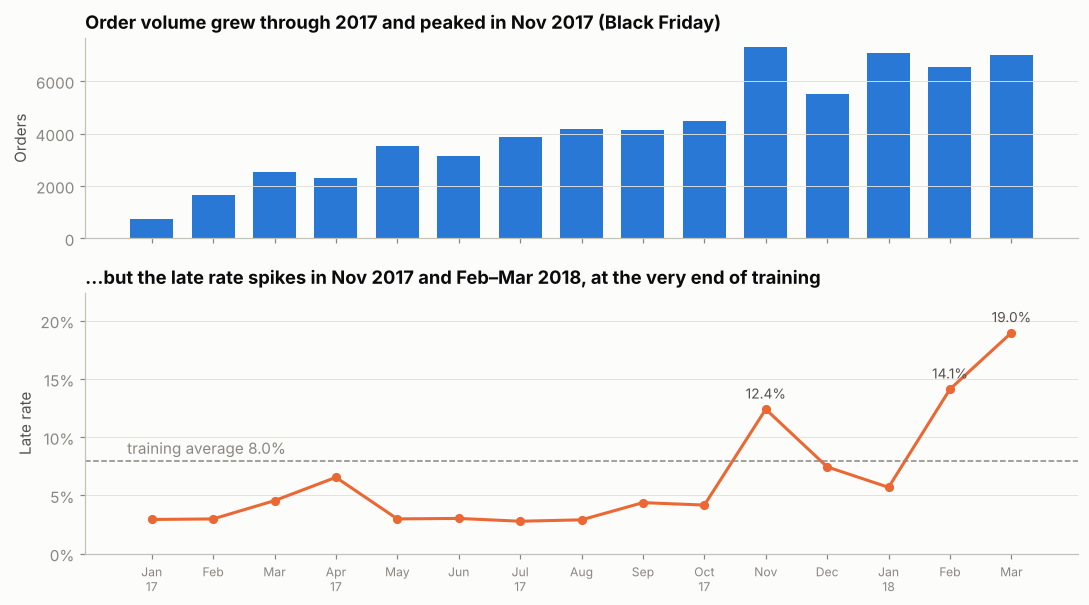

order_purchase_timestamp,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03
orders,748,"1,641","2,546","2,303","3,545","3,135","3,872","4,193","4,150","4,478","7,288","5,513","7,069","6,555","7,002"
late_rate,0.029,0.030,0.046,0.066,0.030,0.030,0.028,0.029,0.044,0.042,0.124,0.075,0.057,0.141,0.190


In [4]:
month = train.order_purchase_timestamp.dt.to_period("M")
monthly = train.groupby(month).agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
labels = [p.strftime("%b\n%y") if p.month in (1, 4, 7, 10) else p.strftime("%b") for p in monthly.index]
x = np.arange(len(monthly))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
a1.bar(x, monthly.orders, color=ON_TIME, width=0.7)
a1.set_ylabel("Orders"); a1.grid(axis="x", visible=False)
a1.set_title("Order volume grew through 2017 and peaked in Nov 2017 (Black Friday)")
a2.plot(x, monthly.late_rate, color=LATE, lw=2, marker="o", ms=5)
a2.axhline(train.is_late.mean(), color=MUTED, ls="--", lw=1)
a2.text(-0.4, train.is_late.mean() + 0.006, f"training average {train.is_late.mean():.1%}", color=MUTED, ha="left")
for i in monthly.late_rate.nlargest(3).index:
    j = list(monthly.index).index(i)
    a2.annotate(f"{monthly.late_rate[i]:.1%}", (j, monthly.late_rate[i]), textcoords="offset points",
                xytext=(0, 7), ha="center", color=INK2, fontsize=9)
a2.set_ylim(0, monthly.late_rate.max() * 1.18); a2.yaxis.set_major_formatter(pct); a2.set_ylabel("Late rate")
a2.set_title("…but the late rate spikes in Nov 2017 and Feb–Mar 2018, at the very end of training")
a2.set_xticks(x); a2.set_xticklabels(labels, fontsize=8); a2.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "02_monthly_volume_and_late_rate")
display(monthly.T.style.format("{:.3f}", subset=pd.IndexSlice["late_rate", :]).format("{:,.0f}", subset=pd.IndexSlice["orders", :]))

**Takeaway: lateness comes in waves, and the biggest wave ends the training period.**
* From Jan to Oct 2017 the late rate stays between **2.8% and 4.6%** (Apr 2017, at 6.6%, is the only exception). Then come **Nov 2017 (12.4%)**, **Feb 2018 (14.1%)** and **Mar 2018 (19.0%)**.
* **The three spike months hold 33% of training orders but 62% of the late ones.**
* Nov 2017 is the busiest month (7,288 orders, Black Friday), so overload is a plausible cause. Feb–Mar 2018 had volume similar to Jan 2018 (5.7%) but 2.5 times (Feb) and 3.3 times (Mar) the late rate.
* **The spikes look largely system-wide:** median approval-to-delivery time stretched from 11.2 days in Jan 2018 to 14.0 in Feb, and even São Paulo's late rate nearly tripled (3.4% in Jan → 9.4% in Mar). **But not entirely:** March also had the shortest median promise of any training month (21.0 days vs 25.4 in Jan), and promise length *is* an order-level feature. So the model can catch part of the March spike, but not the slowdown itself.
* These shocks sit right before the test period begins.

### 2b. What the time-series CV folds look like (D7)

Because the late rate moves so much month to month, each CV validation fold has a different base rate. Everyone comparing models on PR-AUC should know this before reading a fold-by-fold table.

fold,train_orders,train_late_rate,validation_period,val_orders,val_late_rate
1,"8,673",4.5%,31 May 2017 – 27 Aug 2017,"10,673",2.8%
2,"19,346",3.6%,27 Aug 2017 – 10 Nov 2017,"10,673",4.2%
3,"30,019",3.7%,10 Nov 2017 – 26 Dec 2017,"10,673",11.5%
4,"40,692",5.7%,26 Dec 2017 – 14 Feb 2018,"10,673",6.3%
5,"51,365",5.6%,14 Feb 2018 – 31 Mar 2018,"10,673",18.8%


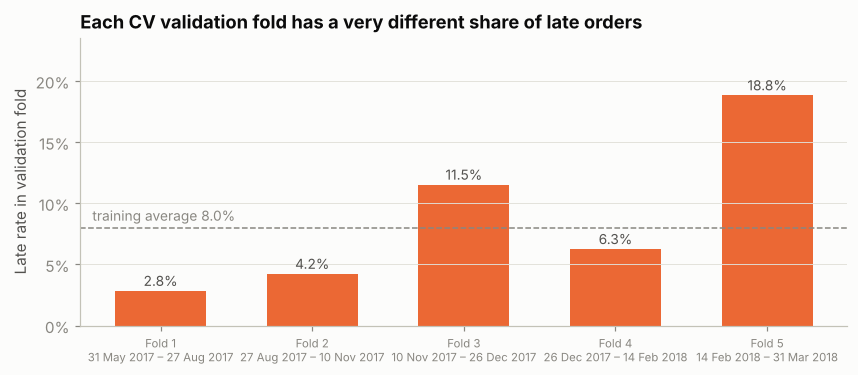

In [5]:
SPLITS = list(cv_splitter().split(train))
fold_rows = []
for k, (tr, va) in enumerate(SPLITS, 1):
    t, v = train.iloc[tr], train.iloc[va]
    fold_rows.append({"fold": k, "train_orders": len(tr), "train_late_rate": t.is_late.mean(),
                      "validation_period": f"{v.order_purchase_timestamp.min():%d %b %Y} – {v.order_purchase_timestamp.max():%d %b %Y}",
                      "val_orders": len(va), "val_late_rate": v.is_late.mean()})
folds = pd.DataFrame(fold_rows)
display(folds.style.format({"train_orders": "{:,}", "val_orders": "{:,}",
                            "train_late_rate": "{:.1%}", "val_late_rate": "{:.1%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(folds.fold, folds.val_late_rate, color=LATE, width=0.6)
ax.axhline(train.is_late.mean(), color=MUTED, ls="--", lw=1)
ax.text(0.55, train.is_late.mean() + 0.006, f"training average {train.is_late.mean():.1%}", color=MUTED, ha="left", fontsize=9)
for f, r, p in zip(folds.fold, folds.val_late_rate, folds.validation_period):
    ax.text(f, r + 0.004, f"{r:.1%}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(folds.fold); ax.set_xticklabels([f"Fold {f}\n{p}" for f, p in zip(folds.fold, folds.validation_period)], fontsize=7.5)
ax.yaxis.set_major_formatter(pct); ax.set_ylabel("Late rate in validation fold")
ax.set_ylim(0, folds.val_late_rate.max() * 1.25); ax.grid(axis="x", visible=False)
ax.set_title("Each CV validation fold has a very different share of late orders")
save(fig, "02b_cv_fold_late_rates")

**Takeaway: fold base rates range from 2.8% to 18.8%, which changes how CV scores should be read.**
* Fold 3 (10 Nov – 26 Dec 2017) contains Black Friday at **11.5%** late. Fold 5 (14 Feb – 31 Mar 2018) contains the spring spike at **18.8%**. Folds 1, 2 and 4 run at 2.8–6.3%.
* A no-skill model's PR-AUC equals the fold's late rate, so **raw PR-AUC will look much better in folds 3 and 5 just because late orders are common there**. Averaging raw PR-AUC across folds mixes very different difficulty levels. Fidan's shortlisting rule of **PR-AUC lift over each fold's late rate** is the right comparison, and every model table should use it.
* The test period (4.1%) looks like folds 1, 2 and 4, not like folds 3 and 5. Expect lower raw test PR-AUC than the CV average. That is drift, not necessarily a worse model (README section 7 already lists this).

## 3. Leakage audit: what is known at approval (D5, D10)

Each column is classified before profiling so teammates know which ones may enter the model.

In [6]:
roles = {
    "order_id": ("Identifier", "Y"), "customer_id": ("Identifier", "Y"),
    "order_purchase_timestamp": ("Raw timestamp", "Y"), "order_approved_at": ("Raw timestamp", "Y"),
    "order_estimated_delivery_date": ("Raw timestamp", "Y"),
    "order_delivered_customer_date": ("LEAKAGE: known only after delivery", "N"),
    "is_late": ("Target", "N"),
}
role = {c: roles.get(c, ("Feature", "Y")) for c in df.columns}
leak_tbl = pd.DataFrame([(c, *role[c]) for c in df.columns], columns=["column", "role", "known_at_approval"])
display(leak_tbl.groupby(["role", "known_at_approval"]).column.apply(lambda s: ", ".join(s)).to_frame("columns"))
banned_present = [c for c in config.BANNED_FEATURE_COLUMNS if c in df.columns]
print("Columns from config.BANNED_FEATURE_COLUMNS present in olist_final.csv:", banned_present)

,,columns
role,known_at_approval,
Feature,Y,"promised_days_from_approval, approval_lag_hour..."
Identifier,Y,"order_id, customer_id"
LEAKAGE: known only after delivery,N,order_delivered_customer_date
Raw timestamp,Y,"order_purchase_timestamp, order_approved_at, o..."
Target,N,is_late


Columns from config.BANNED_FEATURE_COLUMNS present in olist_final.csv: ['order_delivered_customer_date']


**Takeaway.** 22 of the 29 columns are approval-time features. One column, `order_delivered_customer_date`, is the only item on `config.BANNED_FEATURE_COLUMNS` present in the file, and it must never enter the model. The three raw timestamps are known at approval but should be used only through their derived features (`promised_days_from_approval`, `approval_lag_hours`, month/weekday/hour). None of the 22 features uses delivery outcomes, so the feature set is D10-clean as it stands. D10 only becomes relevant if someone adds seller or route history (§10).

## 4. Profiling table: every attribute

For each column: source Olist table, whether it is known at approval, type, bounds, % missing, cardinality, summary statistics, skew, share of 1.5×IQR outliers, noise/quality notes, distribution shape and **usefulness**. All statistics use the training period.

**How usefulness is measured.** Each feature is used on its own to rank orders, scored by ROC-AUC (0.50 = no better than random) on the **5 time-series CV validation folds**, reported as mean ± std:
* Numeric feature: its direction (does a higher value mean more or less risk?) is learned from the fold's *training* part, then applied to the validation part. A feature whose relationship flips over time can score below 0.50.
* Categorical feature: a smoothed late rate per category is fitted on the fold's training part and applied to the validation part, so no category sees its own future.

In [7]:
target = "is_late"
y = train[target]
features = [c for c in df.columns if role[c][0] == "Feature"]
cat_cols = ["customer_state", "any_seller_state", "primary_product_category", "customer_zip_code_prefix"]
num_cols = [c for c in features if c not in cat_cols]

def cv_auc(s, kind, m=20):
    # Univariate ROC-AUC on the D7 time-series folds. Returns (mean, std, per-fold list).
    s = s.reset_index(drop=True); out = []
    for tr, va in SPLITS:
        y_tr, y_va = y.iloc[tr], y.iloc[va]
        if kind == "num":
            x_tr = s.iloc[tr].fillna(s.iloc[tr].median()); x_va = s.iloc[va].fillna(s.iloc[tr].median())
            sign = np.sign(x_tr.rank().corr(y_tr.rank())) or 1.0       # direction learned on the training part
            score = sign * x_va
        else:
            st = s.fillna("__missing__").astype(str); prior = y_tr.mean()
            g = y_tr.groupby(st.iloc[tr]).agg(["sum", "count"])
            score = st.iloc[va].map((g["sum"] + m * prior) / (g["count"] + m)).fillna(prior)
        out.append(roc_auc_score(y_va, score))
    return np.mean(out), np.std(out), out

auc = {c: cv_auc(train[c], "num") for c in num_cols}
auc.update({c: cv_auc(train[c], "cat") for c in cat_cols})

In [8]:
t = train
def q(c, p): return t[c].quantile(p)
src = {
 "order_id": "orders", "customer_id": "orders", "order_purchase_timestamp": "orders", "order_approved_at": "orders",
 "order_delivered_customer_date": "orders", "order_estimated_delivery_date": "orders", "is_late": "orders (derived, D3)",
 "promised_days_from_approval": "orders (derived)", "approval_lag_hours": "orders (derived)",
 "purchase_month": "orders (derived)", "purchase_weekday": "orders (derived)", "purchase_hour": "orders (derived)",
 "approval_month": "orders (derived)", "customer_zip_code_prefix": "customers", "customer_state": "customers",
 "item_count": "order_items (aggregated)", "distinct_product_count": "order_items (aggregated)",
 "seller_count": "order_items (aggregated)", "total_price": "order_items (aggregated)", "total_freight": "order_items (aggregated)",
 "mean_product_weight_g": "products (aggregated)", "max_product_weight_g": "products (aggregated)",
 "total_product_volume_cm3": "products (aggregated)", "mean_distance_km": "geolocation + sellers + customers",
 "max_distance_km": "geolocation + sellers + customers", "same_state_item_share": "sellers + customers",
 "any_seller_state": "sellers", "primary_product_category": "products + category_translation",
 "freight_to_price_ratio": "order_items (derived)",
}
top = lambda c: t[c].value_counts(normalize=True)
notes = {  # (type, bounds, noise / quality, distribution)
 "order_id": ("str (hash)", "—", "Unique key", "—"),
 "customer_id": ("str (hash)", "—", "Unique per order, so no customer history", "—"),
 "order_purchase_timestamp": ("datetime", f"{t.order_purchase_timestamp.min():%Y-%m-%d} → {t.order_purchase_timestamp.max():%Y-%m-%d}", "None observed", "Rising volume, Nov 2017 peak"),
 "order_approved_at": ("datetime", f"{t.order_approved_at.min():%Y-%m-%d} → {t.order_approved_at.max():%Y-%m-%d}", "None observed", "Tracks purchase time"),
 "order_delivered_customer_date": ("datetime", "—", "Post-outcome", "—"),
 "order_estimated_delivery_date": ("date (no time of day)", f"{t.order_estimated_delivery_date.min():%Y-%m-%d} → {t.order_estimated_delivery_date.max():%Y-%m-%d}", "Day precision, hence the calendar-day target (D3)", "—"),
 "is_late": ("binary int", "{0, 1}", "Calendar-day rule (D3)", f"Bernoulli, p = {t.is_late.mean():.3f}"),
 "promised_days_from_approval": ("float, continuous", "> 0", f"Right tail to {t.promised_days_from_approval.max():.0f} days", f"Bell-shaped core (median {t.promised_days_from_approval.median():.1f} d), right tail"),
 "approval_lag_hours": ("float, continuous", "≥ 0", f"Extreme tail to {t.approval_lag_hours.max():.0f} h", "Two groups: most approved within 1 h, a second group after ~1–2 days"),
 "purchase_month": ("int, cyclical", "1–12", "Jan–Mar appear twice (2017 and 2018), other months once", "Uneven"),
 "purchase_weekday": ("int, cyclical", "0–6 (Mon = 0)", "None observed", "Near-uniform, fewer weekend orders"),
 "purchase_hour": ("int, cyclical", "0–23", "None observed", "Daytime plateau, overnight trough"),
 "approval_month": ("int, cyclical", "1–12", f"Equals purchase_month for {(t.purchase_month == t.approval_month).mean():.1%} of orders", "Same as purchase_month"),
 "customer_zip_code_prefix": ("int stored, nominal code", f"{t.customer_zip_code_prefix.min()}–{t.customer_zip_code_prefix.max()}", "Numeric value has no meaning", f"{t.customer_zip_code_prefix.nunique():,} levels, long tail"),
 "customer_state": ("categorical", f"{t.customer_state.nunique()} states", "None observed", f"SP {top('customer_state')['SP']:.0%}, RJ {top('customer_state')['RJ']:.0%}, MG {top('customer_state')['MG']:.0%}"),
 "item_count": ("int, count", "≥ 1", f"Few large baskets (max {t.item_count.max()})", f"{(t.item_count == 1).mean():.0%} single-item"),
 "distinct_product_count": ("int, count", "≥ 1", "—", f"{(t.distinct_product_count == 1).mean():.0%} single-product"),
 "seller_count": ("int, count", "≥ 1", "Multi-seller orders rarely late (small sample, see §4)", f"{(t.seller_count == 1).mean():.1%} single-seller"),
 "total_price": ("float, continuous (BRL)", "> 0", f"Outliers to R${t.total_price.max():,.0f}", "Log-normal, right-skewed"),
 "total_freight": ("float, continuous (BRL)", "≥ 0", f"{(t.total_freight == 0).sum()} zero-freight orders (free shipping); outliers to R${t.total_freight.max():,.0f}", "Log-normal with a spike at 0"),
 "mean_product_weight_g": ("float, continuous", "> 0", "Seller-entered; heaped at round values", "Log-normal, heaped"),
 "max_product_weight_g": ("float, continuous", "> 0", "Identical to mean for single-product orders", "Log-normal, heaped"),
 "total_product_volume_cm3": ("float, continuous", "≥ 0", f"{(t.total_product_volume_cm3 == 0).sum()} orders stored as 0 (missing product dimensions); outliers to {t.total_product_volume_cm3.max():,.0f} cm³", "Log-normal"),
 "mean_distance_km": ("float, continuous", "≥ 0", f"Straight-line between zip centroids; {(t.mean_distance_km > 4500).sum()} values > 4,500 km (beyond Brazil, geocoding errors)", "Right-skewed, cluster of short SP→SP trips"),
 "max_distance_km": ("float, continuous", "≥ 0", f"Equals mean for {(t.mean_distance_km == t.max_distance_km).mean():.0%} of orders", "Same as mean_distance_km"),
 "same_state_item_share": ("float, bounded", "0–1", f"Effectively binary ({t.same_state_item_share.isin([0, 1]).mean():.1%} are 0 or 1)", "Two spikes, at 0 and 1"),
 "any_seller_state": ("categorical", f"{t.any_seller_state.nunique()} states", "One state even for multi-seller orders", f"SP {top('any_seller_state')['SP']:.0%}"),
 "primary_product_category": ("categorical", f"{t.primary_product_category.nunique()} levels", "Long tail of rare categories", "Long-tailed"),
 "freight_to_price_ratio": ("float, continuous", "≥ 0", f"Explodes for very cheap items (max {t.freight_to_price_ratio.max():.1f}×)", "Right-skewed"),
}

def iqr_share(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() if iqr > 0 else 0.0

def usefulness(c):
    r = role[c][0]
    if r != "Feature":
        return {"Target": "Target", "Identifier": "Exclude (ID)", "Raw timestamp": "Exclude (raw; use derived features)"}.get(r, "Exclude (leakage)")
    a = auc[c][0]
    return "High" if a >= 0.58 else "Medium" if a >= 0.53 else "Low"

rows = []
for c in df.columns:
    s = t[c]; isnum = pd.api.types.is_numeric_dtype(s) and c not in cat_cols
    typ, bounds, noise, dist = notes[c]
    rows.append({"column": c, "source_table": src[c], "known_at_approval": role[c][1], "type": typ, "bounds": bounds,
                 "pct_missing": s.isna().mean() * 100, "n_unique": s.nunique(),
                 "min": s.min() if isnum else None, "median": s.median() if isnum else None, "max": s.max() if isnum else None,
                 "skew": s.skew() if isnum else None,
                 "pct_iqr_outliers": iqr_share(s) * 100 if isnum and c != target else None,
                 "noise_quality": noise, "distribution": dist,
                 "auc_mean": auc[c][0] if c in auc else None, "auc_std": auc[c][1] if c in auc else None,
                 "usefulness": usefulness(c)})
profile = pd.DataFrame(rows)
profile.to_csv(TABLE_DIR / "eda_profiling_table.csv", index=False)
fmt = {"pct_missing": "{:.2f}%", "n_unique": "{:,}", "min": "{:,.2f}", "median": "{:,.2f}", "max": "{:,.2f}",
       "skew": "{:.1f}", "pct_iqr_outliers": "{:.1f}%", "auc_mean": "{:.3f}", "auc_std": "± {:.3f}"}
display(profile.style.format(fmt, na_rep="—").hide(axis="index"))

column,source_table,known_at_approval,type,bounds,pct_missing,n_unique,min,median,max,skew,pct_iqr_outliers,noise_quality,distribution,auc_mean,auc_std,usefulness
order_id,orders,Y,str (hash),—,0.00%,"64,038",—,—,—,—,—,Unique key,—,—,—,Exclude (ID)
customer_id,orders,Y,str (hash),—,0.00%,"64,038",—,—,—,—,—,"Unique per order, so no customer history",—,—,—,Exclude (ID)
order_purchase_timestamp,orders,Y,datetime,2017-01-05 → 2018-03-31,0.00%,"63,678",—,—,—,—,—,None observed,"Rising volume, Nov 2017 peak",—,—,Exclude (raw; use derived features)
order_approved_at,orders,Y,datetime,2017-01-05 → 2018-04-03,0.00%,"60,016",—,—,—,—,—,None observed,Tracks purchase time,—,—,Exclude (raw; use derived features)
order_delivered_customer_date,orders,N,datetime,—,0.00%,"63,497",—,—,—,—,—,Post-outcome,—,—,—,Exclude (leakage)
order_estimated_delivery_date,orders,Y,date (no time of day),2017-02-01 → 2018-07-12,0.00%,321,—,—,—,—,—,"Day precision, hence the calendar-day target (D3)",—,—,—,Exclude (raw; use derived features)
is_late,"orders (derived, D3)",N,binary int,"{0, 1}",0.00%,2,0.00,0.00,1.00,3.1,—,Calendar-day rule (D3),"Bernoulli, p = 0.080",—,—,Target
promised_days_from_approval,orders (derived),Y,"float, continuous",> 0,0.00%,"60,493",0.50,23.36,153.58,1.3,2.2%,Right tail to 154 days,"Bell-shaped core (median 23.4 d), right tail",0.492,± 0.030,Low
approval_lag_hours,orders (derived),Y,"float, continuous",≥ 0,0.00%,"22,516",0.00,0.30,741.44,5.2,11.0%,Extreme tail to 741 h,"Two groups: most approved within 1 h, a second group after ~1–2 days",0.540,± 0.015,Medium
purchase_month,orders (derived),Y,"int, cyclical",1–12,0.00%,12,1.00,6.00,12.00,0.2,0.0%,"Jan–Mar appear twice (2017 and 2018), other months once",Uneven,0.519,± 0.030,Low


**Takeaway: profiling summary (training period).**
* **Missingness is small:** `primary_product_category` 1.83%, distance 0.52%, weight 0.02%. Nothing needs to be dropped for missingness.
* **Skew is the main issue:** price (skew 11.1), freight (8.7), volume (7.7), approval lag (5.2), freight-to-price ratio (3.7), weight (3.6). Between 6.8% and 14.6% of their values fall outside 1.5×IQR, but these are real orders (big baskets, heavy items, slow approvals), not errors. A log transform fits better than deleting them, which matches Mia's 3.1b/3.2c.
* **Three near-duplicate pairs** (§8): mean/max distance (ρ = 1.00), mean/max weight (1.00), purchase/approval month (0.99).
* **Usefulness** (each feature on its own, ROC-AUC averaged over the 5 time-series folds):
  * **High (≥ 0.58):** `customer_state` 0.633, `mean_distance_km` 0.591, `total_freight` 0.584. All are geography, directly or indirectly.
  * **Medium (0.53–0.58):** `same_state_item_share` 0.571, `customer_zip_code_prefix` 0.555, `approval_lag_hours` 0.540, weight 0.537, `total_price` 0.535.
  * **Low (< 0.53):** volume, weekday, month, product category (0.513), seller state (0.513), hour, basket counts, and `promised_days_from_approval` (0.492) and `freight_to_price_ratio` (0.488), which score *below* 0.5 on their own (see §6).
* **Calendar and high-cardinality features generalise poorly over time.** Month scores 0.519 with the widest spread (± 0.030), and zip code (13,584 levels) trails customer state (0.633) at 0.555. Geography and freight hold up across folds, which suggests they reflect lasting causes rather than one-off patterns.

In [9]:
issues = pd.DataFrame([
  ("Missing distance (zip prefix not in geolocation table)", "mean/max_distance_km", t.mean_distance_km.isna().sum(), "Impute median inside the pipeline + add a missing flag"),
  ("Missing product category", "primary_product_category", t.primary_product_category.isna().sum(), "Own level 'unknown'"),
  ("Missing product weight", "mean/max_product_weight_g", t.mean_product_weight_g.isna().sum(), "Impute median inside the pipeline"),
  ("Distance > 4,500 km (beyond Brazil's extent: geocoding error)", "mean/max_distance_km", (t.max_distance_km > 4500).sum(), "Set to NaN, then impute"),
  ("Volume stored as 0 (missing product dimensions; same orders as missing weight)", "total_product_volume_cm3", (t.total_product_volume_cm3 == 0).sum(), "Set to NaN, then impute"),
  ("Zero distance (seller and customer share a zip prefix)", "mean_distance_km", (t.mean_distance_km == 0).sum(), "Plausible; keep"),
  ("Zero freight (free shipping)", "total_freight", (t.total_freight == 0).sum(), "Plausible; keep (log1p handles 0)"),
  ("Approval lag > 7 days", "approval_lag_hours", (t.approval_lag_hours > 168).sum(), "Keep; log1p + cap"),
  ("Promised window > 60 days", "promised_days_from_approval", (t.promised_days_from_approval > 60).sum(), "Keep; cap"),
  ("approval_month differs from purchase_month", "approval_month", (t.purchase_month != t.approval_month).sum(), "Redundant; drop approval_month"),
  ("Multi-seller orders rarely late (only 12 late in train)", "seller_count", (t.seller_count > 1).sum(), "Real pattern but tiny sample; keep as a flag, don't over-read"),
], columns=["issue", "column", "orders_in_train", "recommended_handling"])
issues["pct_of_train"] = issues.orders_in_train / len(t) * 100
issues.to_csv(TABLE_DIR / "eda_data_quality_issues.csv", index=False)
display(issues.style.format({"orders_in_train": "{:,}", "pct_of_train": "{:.2f}%"}).hide(axis="index"))
print(f"Late rate when distance is missing: {t[t.mean_distance_km.isna()].is_late.mean():.1%}  vs  overall {t.is_late.mean():.1%}")
print(f"Late rate, multi-seller orders: {t[t.seller_count > 1].is_late.mean():.1%} ({t[t.seller_count > 1].is_late.sum()} late of {(t.seller_count > 1).sum()})  vs  single-seller: {t[t.seller_count == 1].is_late.mean():.1%}")
print(f"Zero-volume orders that also have missing weight: {((t.total_product_volume_cm3 == 0) & t.mean_product_weight_g.isna()).sum()} of {(t.total_product_volume_cm3 == 0).sum()}")

issue,column,orders_in_train,recommended_handling,pct_of_train
Missing distance (zip prefix not in geolocation table),mean/max_distance_km,330,Impute median inside the pipeline + add a missing flag,0.52%
Missing product category,primary_product_category,"1,169",Own level 'unknown',1.83%
Missing product weight,mean/max_product_weight_g,16,Impute median inside the pipeline,0.02%
"Distance > 4,500 km (beyond Brazil's extent: geocoding error)",mean/max_distance_km,3,"Set to NaN, then impute",0.00%
Volume stored as 0 (missing product dimensions; same orders as missing weight),total_product_volume_cm3,16,"Set to NaN, then impute",0.02%
Zero distance (seller and customer share a zip prefix),mean_distance_km,13,Plausible; keep,0.02%
Zero freight (free shipping),total_freight,10,Plausible; keep (log1p handles 0),0.02%
Approval lag > 7 days,approval_lag_hours,59,Keep; log1p + cap,0.09%
Promised window > 60 days,promised_days_from_approval,144,Keep; cap,0.22%
approval_month differs from purchase_month,approval_month,"1,156",Redundant; drop approval_month,1.81%


Late rate when distance is missing: 10.0%  vs  overall 8.0%
Late rate, multi-seller orders: 1.7% (12 late of 720)  vs  single-seller: 8.1%
Zero-volume orders that also have missing weight: 16 of 16


**Takeaway: data quality.** Every issue affects under 2% of training orders.
* Orders with **missing distance are late more often (10.0% vs 8.0%)**, so a missing-distance flag is worth adding next to the median imputation.
* **The 16 zero-volume orders are missing data, not real zeros:** they are exactly the 16 orders with missing product weight, so their dimensions were blank and became 0 when aggregated. Set them to NaN and impute like the weight.
* **Small conflict with Mia's 3.1b:** her notebook says no impossible values were found, but **3 distances exceed 4,500 km** (longer than Brazil itself, so geocoding errors). Too few to change results; setting them to NaN before imputing would make 3.1 accurate.
* **Multi-seller orders are rarely late: 1.7% vs 8.1%.** It is not a merge artefact (the raw orders table holds a single delivery date per order), but it rests on just **12 late orders out of 720**, so keep it as a flag and don't read much into it.

## 5. Distributions of the numeric attributes, by outcome

On-time (blue) and late (orange) orders, each normalised to its own total so the shapes compare despite the imbalance. Skewed money/size/distance features use a **log axis**, the transformation recommended in §9.

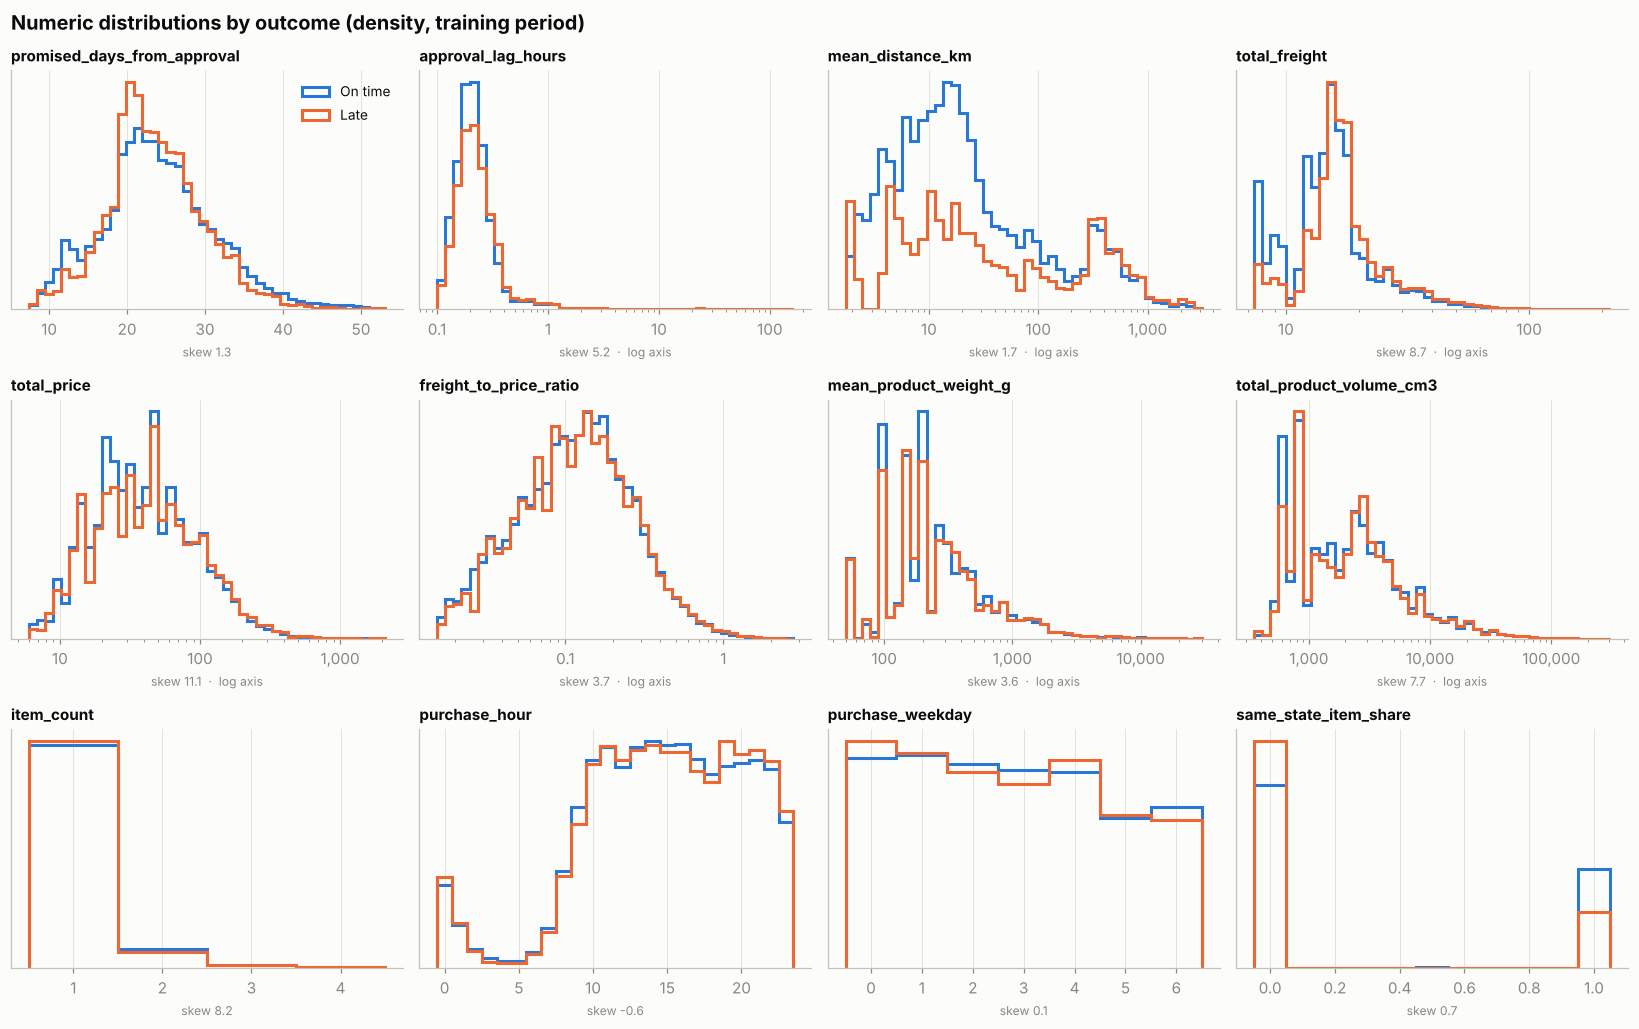

In [10]:
plot_num = ["promised_days_from_approval", "approval_lag_hours", "mean_distance_km", "total_freight",
            "total_price", "freight_to_price_ratio", "mean_product_weight_g", "total_product_volume_cm3",
            "item_count", "purchase_hour", "purchase_weekday", "same_state_item_share"]
log_x = {"approval_lag_hours", "mean_distance_km", "total_freight", "total_price",
         "freight_to_price_ratio", "mean_product_weight_g", "total_product_volume_cm3"}
discrete = {"item_count", "purchase_hour", "purchase_weekday", "same_state_item_share"}
fig, axes = plt.subplots(3, 4, figsize=(15, 9.5))
for ax, c in zip(axes.flat, plot_num):
    s = t[c].dropna()
    if c in discrete:
        bins = np.linspace(-0.05, 1.05, 12) if c == "same_state_item_share" else np.arange(s.min() - 0.5, min(s.quantile(0.995), s.max()) + 1.5, 1)
    elif c in log_x:
        pos = s[s > 0]; bins = np.logspace(np.log10(pos.quantile(0.001)), np.log10(pos.quantile(0.999)), 45)
    else:
        bins = np.linspace(s.quantile(0.001), s.quantile(0.995), 45)
    for lbl, col in [(0, ON_TIME), (1, LATE)]:
        ax.hist(t.loc[t.is_late == lbl, c].dropna(), bins=bins, density=True, histtype="step", lw=2, color=col,
                label="On time" if lbl == 0 else "Late")
    if c in log_x: ax.set_xscale("log"); tidy_log_axis(ax)
    ax.set_title(c, fontsize=10); ax.set_yticks([]); ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"skew {t[c].skew():.1f}" + ("  ·  log axis" if c in log_x else ""), fontsize=8, color=MUTED)
axes.flat[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Numeric distributions by outcome (density, training period)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "03_numeric_distributions_by_outcome")

**Takeaway: distributions.**
* **Distance separates the two classes most visibly.** On-time orders cluster at short distances (São Paulo to São Paulo). Late orders spread toward hundreds and thousands of km. `same_state_item_share` shows the same thing: cross-state orders are late **9.7%** of the time vs **4.6%** for same-state orders.
* `total_freight` follows distance (ρ = 0.58), because Olist charges more for longer routes.
* `promised_days_from_approval`: late orders concentrate in the middle of the range, not at either end (see §6).
* Price, weight, volume, freight ratio, approval lag, hour and weekday: the two curves **mostly overlap**, so each is weak on its own.
* On the log axis, the skewed money and size features look roughly bell-shaped, which supports `log1p`. Weight spikes at round numbers because sellers type in estimates, so treat it as noisy.

## 6. Risk curves: late rate across each numeric feature

Each feature is cut into deciles (equal-count bins). The line shows the late rate per bin, with a 95% confidence band. A flat line on the dashed training average means no signal.

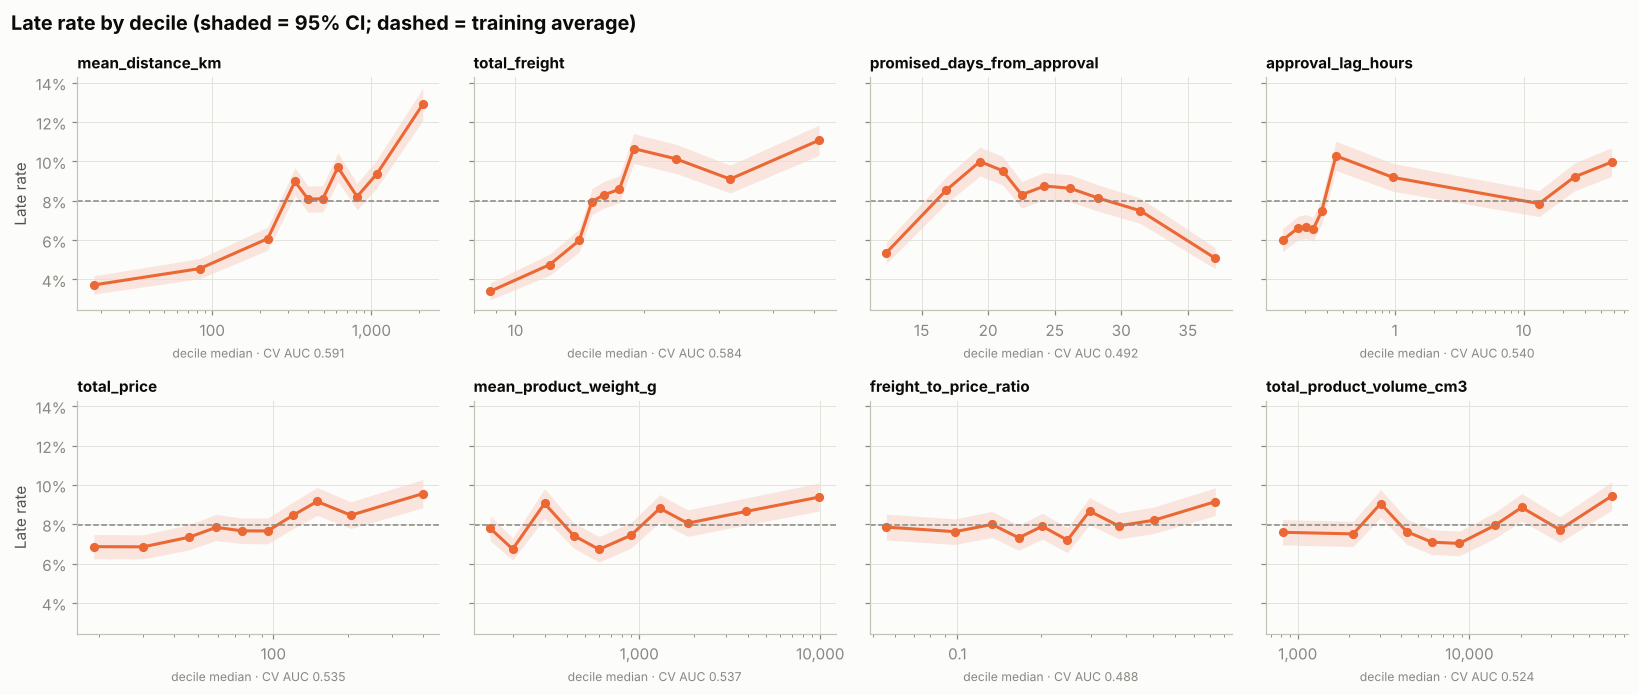

                               D1    D2     D3    D4    D5     D6     D7     D8    D9    D10
mean_distance_km             3.7%  4.6%   6.1%  9.0%  8.1%   8.1%   9.7%   8.2%  9.4%  12.9%
total_freight                3.4%  4.8%   6.0%  8.0%  8.3%   8.6%  10.7%  10.1%  9.1%  11.1%
promised_days_from_approval  5.4%  8.5%  10.0%  9.5%  8.3%   8.7%   8.6%   8.1%  7.5%   5.1%
approval_lag_hours           6.0%  6.6%   6.7%  6.5%  7.5%  10.3%   9.2%   7.9%  9.2%  10.0%
total_price                  6.9%  6.9%   7.3%  7.8%  7.7%   7.7%   8.4%   9.2%  8.5%   9.6%
mean_product_weight_g        7.8%  6.7%   9.1%  7.4%  6.7%   7.4%   8.8%   8.1%  8.7%   9.4%
freight_to_price_ratio       7.9%  7.6%   8.0%  7.3%  7.9%   7.2%   8.7%   7.9%  8.2%   9.1%
total_product_volume_cm3     7.6%  7.5%   9.0%  7.6%  7.1%   7.0%   7.9%   8.9%  7.7%   9.4%


In [11]:
risk_feats = ["mean_distance_km", "total_freight", "promised_days_from_approval", "approval_lag_hours",
              "total_price", "mean_product_weight_g", "freight_to_price_ratio", "total_product_volume_cm3"]
base = t.is_late.mean()
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharey=True)
risk = {}
for ax, c in zip(axes.flat, risk_feats):
    g = t.groupby(pd.qcut(t[c], 10, duplicates="drop"), observed=True).agg(x=(c, "median"), rate=("is_late", "mean"), n=("is_late", "size"))
    risk[c] = g; se = np.sqrt(g.rate * (1 - g.rate) / g.n)
    ax.fill_between(g.x, g.rate - 1.96 * se, g.rate + 1.96 * se, color=LATE, alpha=0.15, lw=0)
    ax.plot(g.x, g.rate, color=LATE, lw=2, marker="o", ms=5); ax.axhline(base, color=MUTED, ls="--", lw=1)
    if c in log_x: ax.set_xscale("log"); tidy_log_axis(ax)
    ax.set_title(c, fontsize=10); ax.yaxis.set_major_formatter(pct)
    ax.set_xlabel(f"decile median · CV AUC {auc[c][0]:.3f}", fontsize=8, color=MUTED)
for ax in axes[:, 0]: ax.set_ylabel("Late rate")
fig.suptitle("Late rate by decile (shaded = 95% CI; dashed = training average)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "04_risk_curves_numeric")
print(pd.DataFrame({c: [f"{v:.1%}" for v in g.rate] for c, g in risk.items()}, index=[f"D{i}" for i in range(1, 11)]).T.to_string())

**Takeaway: risk curves.**
* **Distance is the clearest driver.** The late rate rises from **3.7%** in the nearest decile (under 41 km) to **12.9%** in the farthest (over 1,469 km), about 3.5 times higher.
* **Freight** rises from **3.4% to 11.1%**, levelling off at the top. It is largely a stand-in for distance.
* **Promised days is an inverted U.** The late rate climbs from 5.4% to a peak of **10.0%** at promises of about 18–20 days, then falls back to **5.1%** for the longest promises. Because the curve goes up and then down, ranking orders by this feature alone does no better than chance (AUC 0.492). Tree models handle this shape automatically; a logistic regression needs binning or the ratio feature in §6b/§9.
* **Approval lag** rises from 6.0% to 10.0%. Most orders are approved within an hour (65%), and those approved later carry more risk.
* **Price, weight, freight ratio and volume** mostly stay within about 1.5 points of the 8.0% average. Weak signal.

### 6b. The key interaction: distance × promised window

`promised_days_from_approval` looks weak on its own, because Olist already gives far-away customers longer promises. The useful question is whether the promise is long enough **for that distance**.

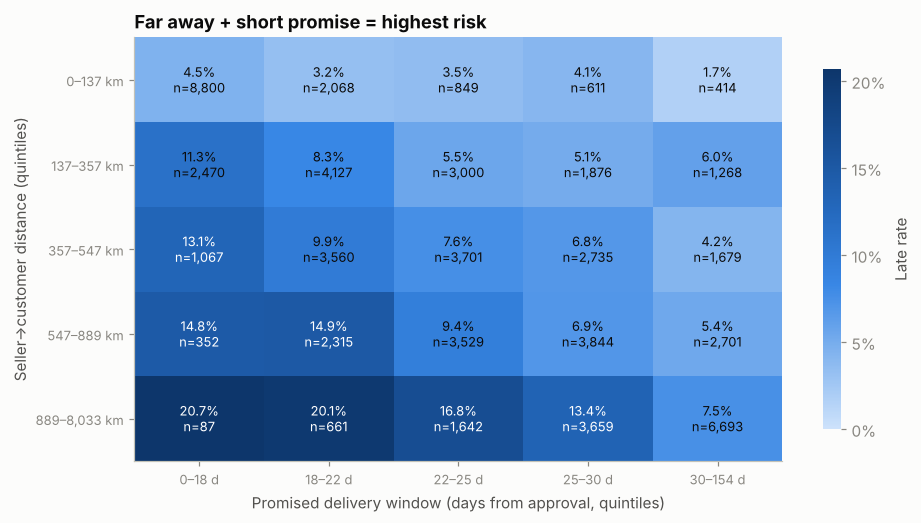

In [12]:
heat = t.pivot_table(index=pd.qcut(t.mean_distance_km, 5), columns=pd.qcut(t.promised_days_from_approval, 5),
                     values="is_late", aggfunc="mean", observed=True)
n = t.pivot_table(index=pd.qcut(t.mean_distance_km, 5), columns=pd.qcut(t.promised_days_from_approval, 5),
                  values="is_late", aggfunc="size", observed=True)
lab = lambda iv, u: f"{max(iv.left, 0):,.0f}–{iv.right:,.0f} {u}"
fig, ax = plt.subplots(figsize=(9.5, 5))
im = ax.imshow(heat.values, cmap=SEQ, aspect="auto", vmin=0, vmax=heat.values.max())
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.1%}\nn={n.values[i, j]:,}", ha="center", va="center", fontsize=8.5,
                color="white" if v > heat.values.max() * 0.55 else INK)
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels([lab(c, "d") for c in heat.columns], fontsize=8.5)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels([lab(r, "km") for r in heat.index], fontsize=8.5)
ax.set_xlabel("Promised delivery window (days from approval, quintiles)"); ax.set_ylabel("Seller→customer distance (quintiles)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, format=pct, shrink=0.85, ticks=np.arange(0, 0.30, 0.05)); cb.set_label("Late rate"); cb.outline.set_visible(False)
ax.set_title("Far away + short promise = highest risk")
save(fig, "05_distance_x_promise_heatmap")

**Takeaway: the headline insight.** Across each row, risk generally falls as the promise gets longer. Down each column, it rises with distance.
* Far (over 889 km) with a promise of 22 days or less: **20.1–20.7% late** (n = 661 and 87).
* Near (under 137 km) with a 30+ day promise: **1.7% late**, a spread of roughly 12 times.
* Neither variable shows this on its own. Olist already gives far customers longer promises (ρ = 0.65), but **not long enough on the longest routes**.
* **Action:** a single *promise relative to distance* feature captures it. In §9, `promise_days_per_100km` scores **AUC 0.614**, up from 0.492 for the raw promise. That makes it the strongest numeric feature, second only to customer state.
* **One-liner for the slides:** *"Late deliveries happen when the promise is too short for the distance."*

## 7. Categorical attributes

Late rate by group, with order counts so small groups are not over-read. The dashed line is the training average.

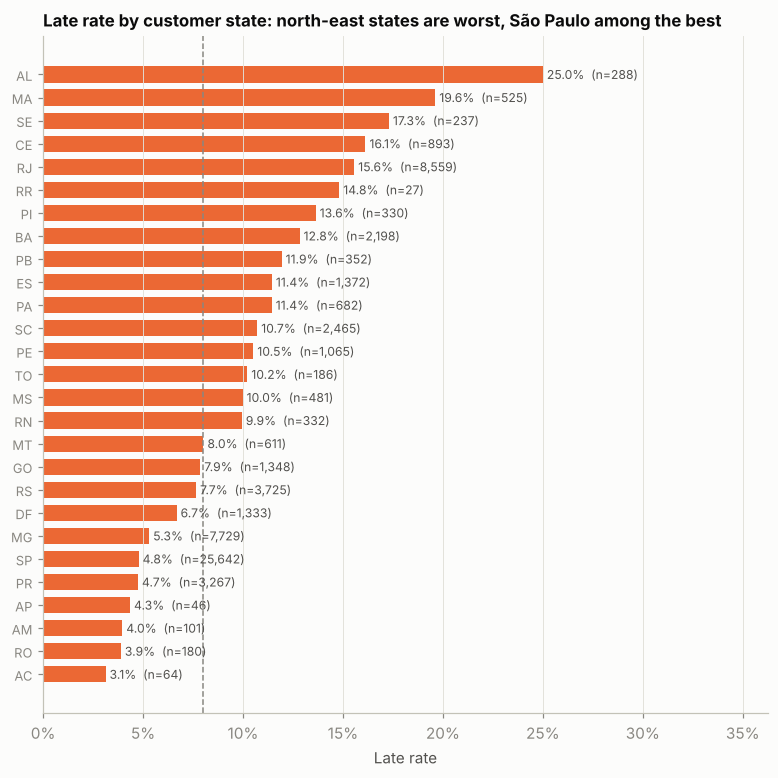

In [13]:
def rate_bars(ax, col, data, top_n=None, min_n=0, title=None):
    g = data.groupby(col).is_late.agg(rate="mean", n="size"); g = g[g.n >= min_n]
    if top_n: g = g.sort_values("n", ascending=False).head(top_n)
    g = g.sort_values("rate")
    ax.barh(g.index.astype(str), g.rate, color=LATE, height=0.7); ax.axvline(base, color=MUTED, ls="--", lw=1)
    for i, (r, k) in enumerate(zip(g.rate, g.n)):
        ax.text(r + 0.002, i, f"{r:.1%}  (n={k:,})", va="center", fontsize=8, color=INK2)
    ax.xaxis.set_major_formatter(pct); ax.set_xlim(0, g.rate.max() * 1.45)
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5); ax.set_title(title or col, fontsize=11)
    return g

fig, ax = plt.subplots(figsize=(8.5, 8))
state_tbl = rate_bars(ax, "customer_state", t, title="Late rate by customer state: north-east states are worst, São Paulo among the best")
ax.set_xlabel("Late rate")
save(fig, "06_late_rate_by_customer_state")

**Takeaway: customer state is the strongest single feature (CV AUC 0.633).**
* North-eastern states are worst: **Alagoas 25.0%, Maranhão 19.6%, Sergipe 17.3%, Ceará 16.1%**, against **São Paulo at 4.8%**, which has 40% of orders. Maranhão is 4.1 times São Paulo's rate and Alagoas 5.2 times.
* **Rio de Janeiro stands out:** **15.6%** late on 8,559 orders, **2.9 times Minas Gerais (5.3%)**, even though Rio's customers are on average *closer* to sellers (median 399 vs 492 km) and get the same promise (23.6 vs 23.9 days). Geography matters **beyond distance**, presumably through regional carrier and last-mile conditions. That is why state adds signal on top of km.
* Small states are noisy (Roraima n = 27, Amapá n = 46), so grouping states with fewer than 100 orders, as Mia does in 3.3b, is sensible.

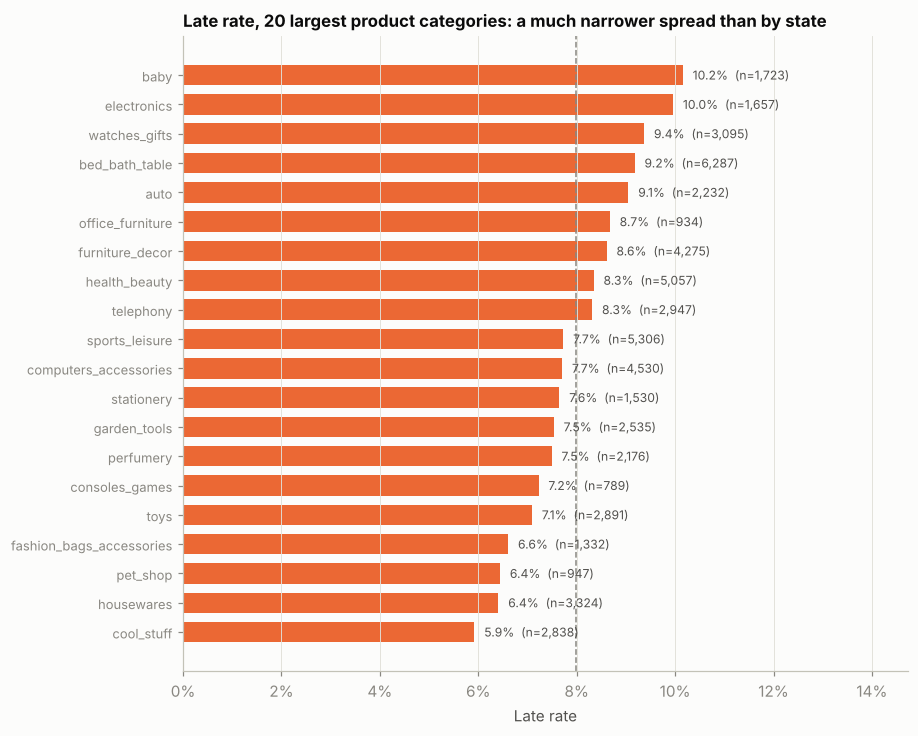

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 7.5))
cat_tbl = rate_bars(ax, "primary_product_category", t, top_n=20, title="Late rate, 20 largest product categories: a much narrower spread than by state")
ax.set_xlabel("Late rate")
save(fig, "07_late_rate_by_category")

**Takeaway: product category barely matters.** The 20 largest categories range from **5.9% (cool_stuff) to 10.2% (baby)**, and category scores just 0.513 under time-series CV. What is shipped matters far less than where it goes. Group rare categories, keep missing as "unknown", and expect category to rank low in importance.

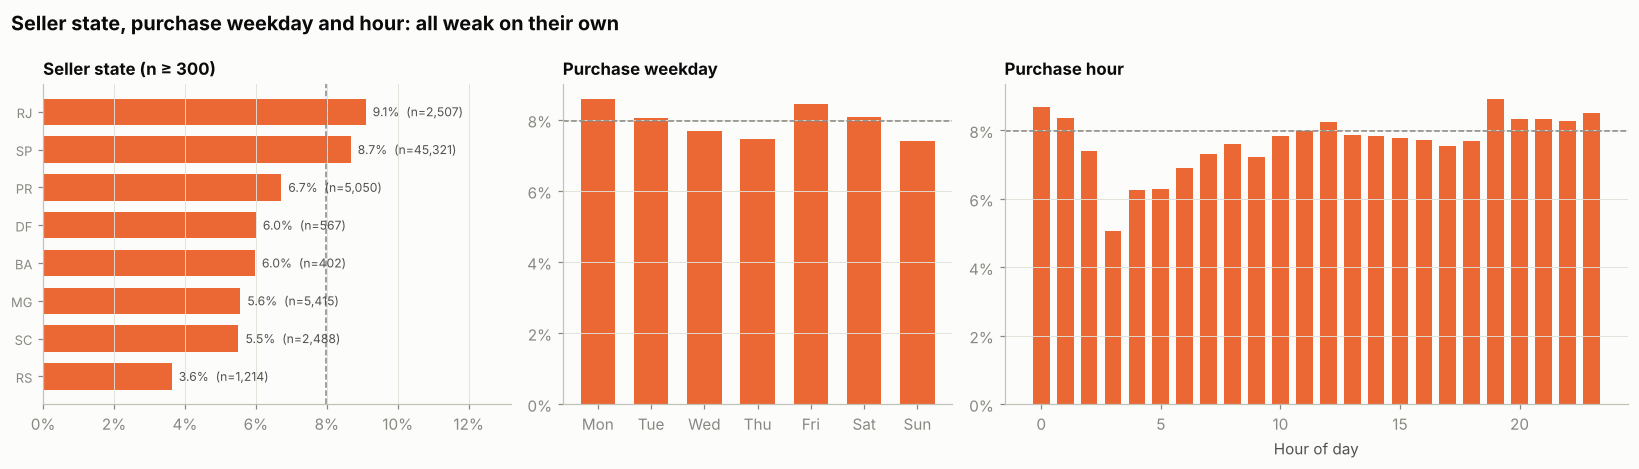

,late rate,orders
1 seller,8.1%,"63,318"
2+ sellers,1.7%,720
1 item,8.1%,"57,627"
2+ items,6.5%,"6,411"


Weekday late rate range: 7.4%–8.6%


In [15]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.2, 1, 1.6]})
seller_tbl = rate_bars(axes[0], "any_seller_state", t, min_n=300, title="Seller state (n ≥ 300)")
wd = t.groupby("purchase_weekday").is_late.agg(rate="mean", n="size")
axes[1].bar(days, wd.rate, color=LATE, width=0.65); axes[1].axhline(base, color=MUTED, ls="--", lw=1)
axes[1].yaxis.set_major_formatter(pct); axes[1].set_title("Purchase weekday", fontsize=11); axes[1].grid(axis="x", visible=False)
hr = t.groupby("purchase_hour").is_late.agg(rate="mean", n="size")
axes[2].bar(hr.index, hr.rate, color=LATE, width=0.7); axes[2].axhline(base, color=MUTED, ls="--", lw=1)
axes[2].yaxis.set_major_formatter(pct); axes[2].set_title("Purchase hour", fontsize=11); axes[2].grid(axis="x", visible=False)
axes[2].set_xlabel("Hour of day")
fig.suptitle("Seller state, purchase weekday and hour: all weak on their own", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "08_seller_state_weekday_hour")
basket = t.assign(sellers=np.where(t.seller_count > 1, "2+ sellers", "1 seller"), items=np.where(t.item_count > 1, "2+ items", "1 item"))
display(pd.concat([basket.groupby("sellers").is_late.agg(["mean", "size"]), basket.groupby("items").is_late.agg(["mean", "size"])])
        .rename(columns={"mean": "late rate", "size": "orders"}).style.format({"late rate": "{:.1%}", "orders": "{:,}"}))
print(f"Weekday late rate range: {wd.rate.min():.1%}–{wd.rate.max():.1%}")

**Takeaway: seller state, timing and basket size are all weak.**
* **Seller state** ranges from **3.6% (RS) to 9.1% (RJ)**, and São Paulo sellers (71% of orders) are slightly above average at 8.7%. On its own it scores only 0.513, because most of its signal is already carried by where the order is going.
* **Weekday (7.4–8.6%) and hour** are close to flat (AUC 0.521 and 0.511). The 3–4 a.m. dip rests on very few orders. Low priority.
* **Baskets:** multi-item orders are a little *less* often late (6.5% vs 8.1%). Multi-seller orders are rarely late (1.7%), but that is only 12 late orders (§4).

## 8. Correlations

**8a.** Spearman rank correlation between numeric attributes (rank-based, so robust to the skew in §5). Used to find **redundant** features.
**8b.** Every feature's time-series-CV usefulness (AUC), numeric and categorical together, ranked: the usefulness column of the profiling table, as a chart.

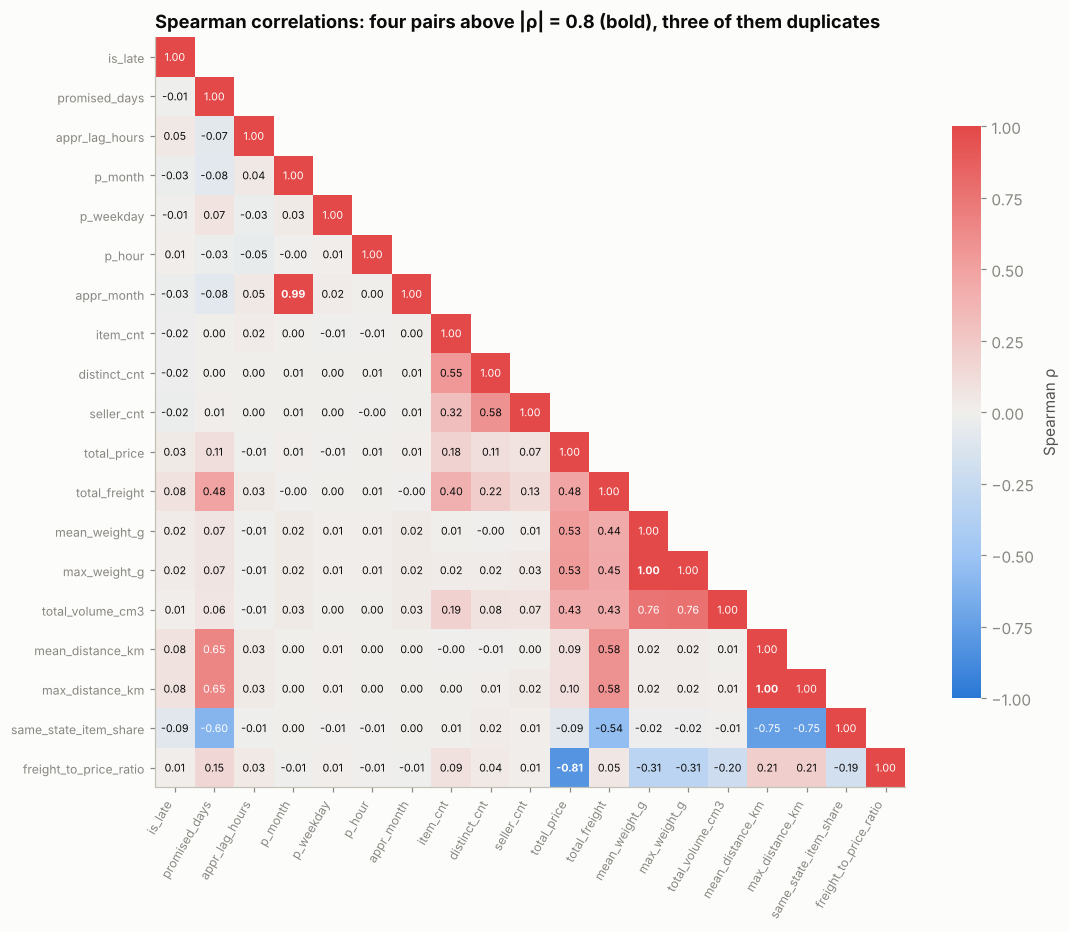

level_0,level_1,rho
max_distance_km,mean_distance_km,1.00
max_product_weight_g,mean_product_weight_g,1.00
approval_month,purchase_month,0.99
freight_to_price_ratio,total_price,-0.81
total_product_volume_cm3,max_product_weight_g,0.76
total_product_volume_cm3,mean_product_weight_g,0.76
same_state_item_share,mean_distance_km,-0.75
same_state_item_share,max_distance_km,-0.75
max_distance_km,promised_days_from_approval,0.65
mean_distance_km,promised_days_from_approval,0.65


Spearman ρ with is_late (top 6 by magnitude):
same_state_item_share   -0.089
mean_distance_km         0.084
total_freight            0.083
max_distance_km          0.083
approval_lag_hours       0.046
total_price              0.030


In [16]:
corr_cols = ["is_late"] + [c for c in num_cols if c != "customer_zip_code_prefix"]
corr = t[corr_cols].corr(method="spearman")
short = {c: c.replace("_from_approval", "").replace("_product", "").replace("_count", "_cnt")
              .replace("purchase_", "p_").replace("approval_", "appr_") for c in corr.columns}
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
im = ax.imshow(np.ma.masked_array(corr.values, mask), cmap=DIV, vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(i + 1):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else INK,
                fontweight="bold" if abs(v) > 0.8 and i != j else "normal")
ax.set_xticks(range(len(corr))); ax.set_xticklabels([short[c] for c in corr.columns], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels([short[c] for c in corr.columns], fontsize=8); ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75); cb.set_label("Spearman ρ"); cb.outline.set_visible(False)
ax.set_title("Spearman correlations: four pairs above |ρ| = 0.8 (bold), three of them duplicates")
save(fig, "09_spearman_correlation_matrix")
pairs = (corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack().rename("rho").reset_index()
         .query("abs(rho) > 0.5").sort_values("rho", key=abs, ascending=False))
display(pairs.style.format({"rho": "{:.2f}"}).hide(axis="index"))
print("Spearman ρ with is_late (top 6 by magnitude):")
print(corr["is_late"].drop("is_late").sort_values(key=abs, ascending=False).head(6).round(3).to_string())

**Takeaway: correlations.**
* **Drop one of each near-duplicate pair:** keep `mean_distance_km`, `mean_product_weight_g` and `purchase_month`, and drop `max_distance_km`, `max_product_weight_g` and `approval_month`. Mia already drops `approval_month`. Dropping the two `max_*` columns as well helps logistic regression.
* **A geography cluster:** distance correlates with the promise (0.65), with freight (0.58) and with same-state share (−0.75), because Olist sets both freight and the promise from distance. This matters for logistic regression (regularise, or use the ratio feature); trees are unaffected.
* `total_price` vs `freight_to_price_ratio` (−0.81) is correlated by construction.
* **No numeric feature has a strong linear relationship with `is_late`:** the largest is |ρ| = 0.089 (`same_state_item_share`), then distance and freight at 0.08. The signal is in **curves and interactions** (§6, §6b). This suggested that tree ensembles or engineered features would beat a plain logistic regression. In the end they did not: the tuned logistic regression won (sections 4.1 and 5.1).

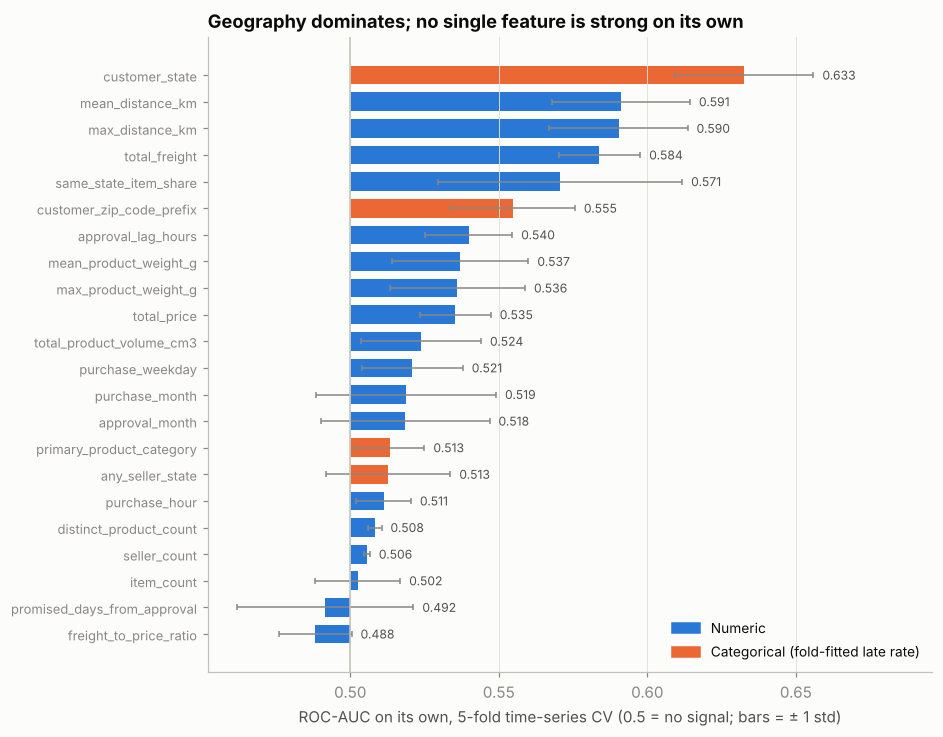

,mean,std
customer_state,0.633,0.023
mean_distance_km,0.591,0.023
max_distance_km,0.590,0.023
total_freight,0.584,0.014
same_state_item_share,0.571,0.041
customer_zip_code_prefix,0.555,0.021
approval_lag_hours,0.540,0.015
mean_product_weight_g,0.537,0.023
max_product_weight_g,0.536,0.023
total_price,0.535,0.012


In [17]:
auc_df = pd.DataFrame({c: {"mean": v[0], "std": v[1]} for c, v in auc.items()}).T.sort_values("mean")
fig, ax = plt.subplots(figsize=(8.5, 7.5))
cols = [LATE if c in cat_cols else ON_TIME for c in auc_df.index]
ax.barh(auc_df.index, auc_df["mean"] - 0.5, left=0.5, color=cols, height=0.7,
        xerr=auc_df["std"], error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 2})
for i, (m_, s_) in enumerate(zip(auc_df["mean"], auc_df["std"])):
    ax.text(max(m_ + s_, 0.5) + 0.003, i, f"{m_:.3f}", va="center", fontsize=8, color=INK2)
ax.axvline(0.5, color=AXIS, lw=1)
ax.set_xlim(min(0.47, (auc_df["mean"] - auc_df["std"]).min() - 0.01), (auc_df["mean"] + auc_df["std"]).max() + 0.04)
ax.set_xlabel("ROC-AUC on its own, 5-fold time-series CV (0.5 = no signal; bars = ± 1 std)")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8.5)
ax.legend(handles=[Patch(color=ON_TIME, label="Numeric"), Patch(color=LATE, label="Categorical (fold-fitted late rate)")], loc="lower right", fontsize=9)
ax.set_title("Geography dominates; no single feature is strong on its own")
save(fig, "10_univariate_auc_ranking")
display(auc_df.sort_values("mean", ascending=False).style.format("{:.3f}"))

**Takeaway: usefulness ranking.** **Geography takes the top five spots** (state, distance ×2, freight, same-state share), with approval lag the best non-geographic feature. Calendar, product and seller attributes sit at the bottom under time-series CV. No feature reaches 0.64 on its own, so predictive power has to come from **combining** them, especially distance with the promise.

## 9. Promising transformations (hand-off to *Prepare the Data*)

Each candidate is scored with the same time-series-CV usefulness AUC. None of them uses delivery outcomes, so none needs history handling under D10. (`promise_slack_vs_state_typical` is deliberately not included: it was built from actual delivery times, which conflicts with D10, and the team agreed to drop it.)

In [18]:
c2 = t.copy()
# Missing distance stays NaN here; cv_auc imputes with each fold's training median (no validation data used)
c2["promise_days_per_100km"] = c2.promised_days_from_approval / (c2.mean_distance_km / 100 + 1)
c2["cross_state"] = (c2.same_state_item_share < 1).astype(int)
region = {**dict.fromkeys(["SP", "RJ", "MG", "ES"], "Southeast"), **dict.fromkeys(["PR", "SC", "RS"], "South"),
          **dict.fromkeys(["DF", "GO", "MT", "MS"], "Center-West"),
          **dict.fromkeys(["BA", "SE", "AL", "PE", "PB", "RN", "CE", "PI", "MA"], "Northeast"),
          **dict.fromkeys(["PA", "AM", "AP", "RR", "AC", "RO", "TO"], "North")}
c2["customer_region"] = c2.customer_state.map(region)
c2["route_region"] = c2.any_seller_state.map(region).fillna("?") + "→" + c2.customer_region
c2["hour_sin"] = np.sin(2 * np.pi * c2.purchase_hour / 24)
c2["is_weekend_purchase"] = (c2.purchase_weekday >= 5).astype(int)
c2["multi_seller"] = (c2.seller_count > 1).astype(int)
c2["distance_missing"] = c2.mean_distance_km.isna().astype(int)
new = {"promise_days_per_100km": "num", "cross_state": "num", "route_region": "cat", "customer_region": "cat",
       "hour_sin": "num", "is_weekend_purchase": "num", "multi_seller": "num", "distance_missing": "num"}
trans = {f"{c} (new)": cv_auc(c2[c], k) for c, k in new.items()}
trans.update({f"{c} (raw)": auc[c] for c in ["customer_state", "mean_distance_km", "promised_days_from_approval"]})
trans_df = pd.DataFrame({k: {"auc_mean": v[0], "auc_std": v[1]} for k, v in trans.items()}).T.sort_values("auc_mean", ascending=False)
display(trans_df.style.format("{:.3f}").bar(subset=["auc_mean"], color="#f5c6b1", vmin=0.5))

,auc_mean,auc_std
customer_state (raw),0.633,0.023
promise_days_per_100km (new),0.614,0.022
mean_distance_km (raw),0.591,0.023
route_region (new),0.573,0.026
cross_state (new),0.570,0.041
customer_region (new),0.553,0.034
is_weekend_purchase (new),0.511,0.012
multi_seller (new),0.506,0.001
distance_missing (new),0.500,0.001
hour_sin (new),0.500,0.012


**Takeaway: transformations, ranked for the *Prepare the Data* stage.**

| Transformation | CV AUC on its own | Recommendation |
|---|---|---|
| `promise_days_per_100km` = promise ÷ (distance/100 + 1) | **0.614** (raw promise 0.492) | **Build it.** Best numeric feature |
| `route_region` (seller region → customer region) | 0.573 | Optional; weaker than customer state alone (0.633) |
| `cross_state` flag | 0.570 | Simple and interpretable; carries the same information as `same_state_item_share` |
| `customer_region` (5 regions) | 0.553 | Loses information compared with state; useful only for grouping rare states |
| Weekend flag, `hour_sin`, multi-seller flag, missing-distance flag | 0.50–0.51 | Low value alone; cheap to include |

**Also recommended for the pipeline** (fitted on training folds only):
* `log1p` on price, freight, weight, volume, distance, approval lag and freight ratio.
* Drop `max_distance_km`, `max_product_weight_g`, `approval_month`, `customer_zip_code_prefix`, the IDs, the raw timestamps and `order_delivered_customer_date`.
* Set the 16 zero volumes (missing dimensions) and 3 impossible distances to NaN, then median-impute. Add a missing-distance flag; use "unknown" for missing category.
* One-hot encode state, seller state and category, grouping levels with fewer than 100 orders.

## 10. Extra data that would help

| Extra data | Why it should help | Usable at approval? | Source |
|---|---|---|---|
| **Seller's past late rate and handling time** | Seller reliability is invisible in a single order | Yes, if built only from orders **delivered before** this order's purchase time (D10) | Raw `orders` + `order_items` |
| **`shipping_limit_date`** (seller's deadline to hand over to the carrier) | A tight dispatch deadline relative to the promise | Yes | Raw `order_items` |
| **Repeat-customer flag** (`customer_unique_id`) | `customer_id` is unique per order, so customer history is lost | Yes | Raw `customers` |
| **Brazilian holiday and disruption calendar** (Black Friday, Carnival, strikes) | The Nov 2017 and Feb–Mar 2018 spikes look largely system-wide (delivery times stretched even in São Paulo) | Yes, for scheduled events | Public calendars, news |
| **Road distance / carrier route** instead of straight-line km | Straight-line distance understates remote northern and north-eastern routes | Yes | Routing API, Correios zone tables |
| **Carrier and service level** | Carriers differ in reliability | In principle | Not in the public data |
| **Payment type** | Likely explains the slow-approval group in `approval_lag_hours` | Unconfirmed, so excluded for now (D1) | Raw `order_payments` |

## 11. Summary of what we learned (training period, Jan 2017 – Mar 2018)

**Key findings**
1. **8.0% of training orders arrive late (about 11.5 to 1).** "Always on time" scores 92% accuracy and catches nothing, so we use PR-AUC and top-10% recall.
2. **"Late deliveries happen when the promise is too short for the distance."** Far orders with short promises run about 20% late; near orders with long promises about 2%. Combining the two (`promise_days_per_100km`) gives the best numeric feature (CV AUC 0.614).
3. **Where the order goes matters most.** Customer state is the strongest single predictor (CV AUC 0.633). Maranhão and Alagoas run 4–5 times São Paulo's late rate.
4. **Rio is late 2.9 times as often as Minas Gerais** despite shorter distances and the same promise, so regional logistics matter beyond kilometres.
5. **What is ordered, who sells it and when it is bought barely matter.** Category, seller state, weight, price, weekday and hour all score 0.51–0.54.
6. **Lateness comes in waves** (Nov 2017 12.4%, Feb–Mar 2018 14.1–19.0%). The three spike months hold 62% of late training orders. They look largely system-wide (delivery times stretched everywhere), though shorter promises in March contributed. The CV folds inherit this: validation late rates range from 2.8% to 18.8%, so models must be compared on **lift over each fold's base rate**, not raw PR-AUC.
7. **No single feature is strong** (best AUC 0.633; largest |ρ| with the target 0.089). The signal is in curves and interactions. We expected this to favour tree ensembles or engineered features, but the tuned logistic regression still won (section 5).

**Assumptions specific to this EDA** (the project-wide ones are in README section 7)
* Straight-line distance between zip-code centroids is a fair stand-in for route length.
* Univariate AUC from the D7 folds is a reasonable guide to usefulness. It ignores interactions, which is why §6b matters.

**Limitations seen in the data, and their likely impact**
* **Unexplained shocks** at the end of the training period, followed by a much calmer test period (4.1%). Raw test PR-AUC will likely fall below the CV average. Report lift, and consider recalibrating the decision threshold.
* **No seller history, carrier or holiday data**, so seller reliability and disruptions are invisible. A D10-compliant seller history looked like the most promising extra feature (§10), but it did not improve the model when we tested it (section 4.4).
* **Noisy seller-entered product data** (weight heaping, zero volumes). Low impact, since product traits matter little.
* **Multi-seller orders** look unusually safe (1.7% late), but on only 12 late orders: too few to rely on.
* **Small states** (under 100 orders) give unreliable per-state rates, so group them.
